In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os

from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    ExtraTreesRegressor
)
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import pandas as pd

file_path = 'india_rainfall_crop_yield_2014_2024 (1).csv'

try:
    df = pd.read_csv(file_path)
    df.columns = df.columns.str.strip()
    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)
    display(df.head())
except FileNotFoundError:
    print(f"File not found at {file_path}. Please check your file system.")

Dataset loaded successfully!
Dataset shape: (7920, 17)


,Record_ID,State,District,Year,Season,Crop_Type,Rainfall_mm,Avg_Temperature_C,Humidity_percent,Soil_Type,Irrigation_Type,Fertilizer_Used_kg,Pesticide_Used_kg,Cultivated_Area_hectares,Yield_ton_per_hectare,Market_Price_per_ton,Farmer_Profit_INR
0,1,Uttarakhand,Dehradun,2014,Kharif,Rice,445.02,23.5,47.3,Black,Sprinkler,344.59,42.22,4471.68,1.83,34361.86,67904.0
1,2,Uttarakhand,Dehradun,2014,Rabi,Wheat,1410.24,32.3,73.6,Red,Rain-fed,217.81,29.71,1463.13,7.55,52216.79,106010.0
2,3,Uttarakhand,Dehradun,2014,Kharif,Maize,787.56,33.3,40.6,Laterite,Canal,201.97,24.74,1785.38,3.13,14302.87,70380.0
3,4,Uttarakhand,Dehradun,2014,Kharif,Cotton,1892.93,30.4,82.4,Alluvial,Tube Well,280.94,43.75,324.54,2.86,27337.56,8166.0
4,5,Uttarakhand,Dehradun,2014,Zaid,Cotton,1216.14,34.7,43.9,Black,Drip,192.11,41.86,3538.92,6.19,15784.33,314345.0


In [3]:
print("Dataset Information")
print("--------------------")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
display(df.dtypes)

print("\nMissing Values:")
display(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

print("\nDescriptive Statistics:")
display(df.describe().T)

Dataset Information
--------------------
Rows: 7920
Columns: 17

Column Names:
['Record_ID', 'State', 'District', 'Year', 'Season', 'Crop_Type', 'Rainfall_mm', 'Avg_Temperature_C', 'Humidity_percent', 'Soil_Type', 'Irrigation_Type', 'Fertilizer_Used_kg', 'Pesticide_Used_kg', 'Cultivated_Area_hectares', 'Yield_ton_per_hectare', 'Market_Price_per_ton', 'Farmer_Profit_INR']

Data Types:


Record_ID                     int64
State                        object
District                     object
Year                          int64
Season                       object
Crop_Type                    object
Rainfall_mm                 float64
Avg_Temperature_C           float64
Humidity_percent            float64
Soil_Type                    object
Irrigation_Type              object
Fertilizer_Used_kg          float64
Pesticide_Used_kg           float64
Cultivated_Area_hectares    float64
Yield_ton_per_hectare       float64
Market_Price_per_ton        float64
Farmer_Profit_INR           float64
dtype: object


Missing Values:


Record_ID                   0
State                       0
District                    0
Year                        0
Season                      0
Crop_Type                   0
Rainfall_mm                 0
Avg_Temperature_C           0
Humidity_percent            0
Soil_Type                   0
Irrigation_Type             0
Fertilizer_Used_kg          0
Pesticide_Used_kg           0
Cultivated_Area_hectares    0
Yield_ton_per_hectare       0
Market_Price_per_ton        0
Farmer_Profit_INR           0
dtype: int64


Duplicate Records:
0

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
Record_ID,7920.0,3960.500000,2286.451399,1.00,1980.7500,3960.500,5940.2500,7920.00
Year,7920.0,2019.000000,3.162477,2014.00,2016.0000,2019.000,2022.0000,2024.00
Rainfall_mm,7920.0,1303.157420,516.667333,400.80,855.2800,1305.420,1752.0575,2199.58
Avg_Temperature_C,7920.0,28.070985,5.806386,18.00,23.0000,28.100,33.2000,38.00
Humidity_percent,7920.0,62.466869,15.817427,35.00,49.0000,62.700,76.0000,90.00
Fertilizer_Used_kg,7920.0,250.312962,114.850492,50.17,149.9575,251.350,350.6925,449.90
Pesticide_Used_kg,7920.0,32.569508,15.916997,5.00,18.6500,32.860,46.3025,59.98
Cultivated_Area_hectares,7920.0,2563.768706,1414.030920,100.65,1331.8425,2567.445,3796.0150,4999.30
Yield_ton_per_hectare,7920.0,4.832213,2.127995,1.20,2.9500,4.850,6.6800,8.50
Market_Price_per_ton,7920.0,38279.748221,15273.022319,12014.35,25045.9675,38261.045,51779.0575,64998.76


In [4]:
target = "Yield_ton_per_hectare"

categorical_features = [
    "State",
    "Season",
    "Crop_Type",
    "Soil_Type",
    "Irrigation_Type"
]

numeric_features = [
    "Rainfall_mm",
    "Avg_Temperature_C",
    "Humidity_percent",
    "Fertilizer_Used_kg",
    "Pesticide_Used_kg",
    "Cultivated_Area_hectares"
]

features = categorical_features + numeric_features

# Remove rows with missing target values
data = df.dropna(subset=[target, "Year"]).copy()

X = data[features].copy()
y = pd.to_numeric(data[target], errors="coerce")

# Convert numeric columns into numeric format
for col in numeric_features:
    X[col] = pd.to_numeric(X[col], errors="coerce")

valid = y.notna()

X = X.loc[valid]
y = y.loc[valid]
data = data.loc[valid]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget Variable:")
print(target)

print("\nTarget Statistics:")
display(y.describe())

Input shape: (7920, 11)
Target shape: (7920,)

Target Variable:
Yield_ton_per_hectare

Target Statistics:


count    7920.000000
mean        4.832213
std         2.127995
min         1.200000
25%         2.950000
50%         4.850000
75%         6.680000
max         8.500000
Name: Yield_ton_per_hectare, dtype: float64

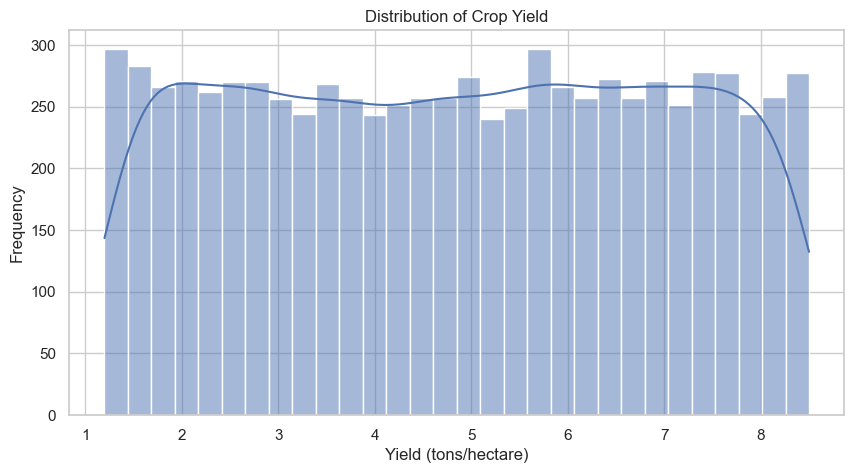

Skewness: -0.006040861016935411
Mean: 4.8322133838383845
Standard Deviation: 2.127994671232924
Minimum: 1.2
Maximum: 8.5


In [5]:
plt.figure(figsize=(10, 5))

sns.histplot(
    y,
    kde=True,
    bins=30
)

plt.title("Distribution of Crop Yield")
plt.xlabel("Yield (tons/hectare)")
plt.ylabel("Frequency")
plt.show()

print("Skewness:", y.skew())
print("Mean:", y.mean())
print("Standard Deviation:", y.std())
print("Minimum:", y.min())
print("Maximum:", y.max())

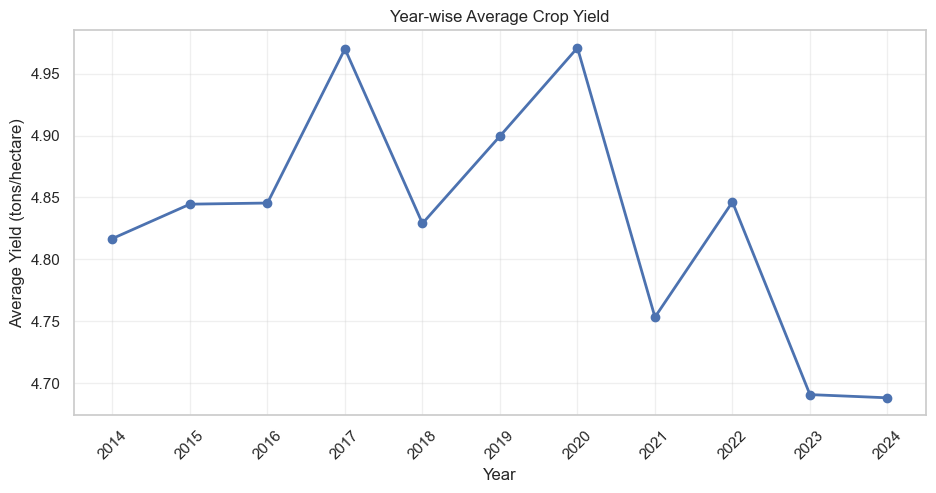

Year
2014    4.816736
2015    4.844528
2016    4.845444
2017    4.970069
2018    4.828958
2019    4.899528
2020    4.970903
2021    4.753222
2022    4.846333
2023    4.690611
2024    4.688014
Name: Yield_ton_per_hectare, dtype: float64

In [6]:
yearly_yield = data.groupby("Year")[target].mean()

plt.figure(figsize=(11, 5))

plt.plot(
    yearly_yield.index,
    yearly_yield.values,
    marker="o",
    linewidth=2
)

plt.title("Year-wise Average Crop Yield")
plt.xlabel("Year")
plt.ylabel("Average Yield (tons/hectare)")
plt.xticks(yearly_yield.index, rotation=45)
plt.grid(alpha=0.3)
plt.show()

display(yearly_yield)

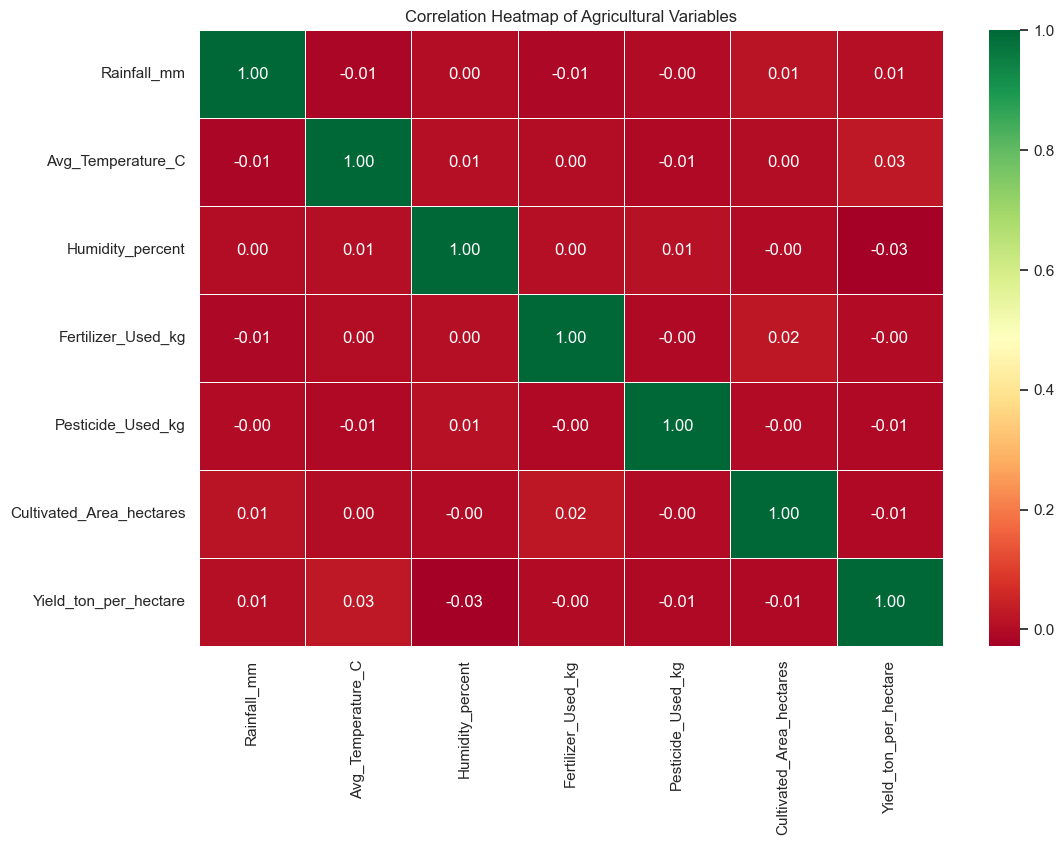

Correlation with Crop Yield:


Yield_ton_per_hectare       1.000000
Avg_Temperature_C           0.025920
Rainfall_mm                 0.006083
Fertilizer_Used_kg         -0.002091
Pesticide_Used_kg          -0.006317
Cultivated_Area_hectares   -0.006887
Humidity_percent           -0.027923
Name: Yield_ton_per_hectare, dtype: float64

In [7]:
correlation_data = data[
    numeric_features + [target]
].copy()

correlation_data = correlation_data.apply(
    pd.to_numeric,
    errors="coerce"
)

correlation_matrix = correlation_data.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="RdYlGn",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Agricultural Variables")
plt.show()

print("Correlation with Crop Yield:")

display(
    correlation_matrix[target]
    .sort_values(ascending=False)
)

In [8]:
train_data = data[data["Year"] < 2024].copy()
test_data = data[data["Year"] == 2024].copy()

X_train = train_data[features]
X_test = test_data[features]

y_train = train_data[target]
y_test = test_data[target]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

print("Training years:",
      train_data["Year"].min(),
      "to",
      train_data["Year"].max())

print("Testing year:",
      test_data["Year"].unique())

Training records: 7200
Testing records: 720
Training years: 2014 to 2023
Testing year: [2024]


In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(strategy="most_frequent")
                ),
                (
                    "encoder",
                    OneHotEncoder(handle_unknown="ignore")
                )
            ]),
            categorical_features
        ),

        (
            "numerical",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(strategy="median")
                ),
                (
                    "scaler",
                    StandardScaler()
                )
            ]),
            numeric_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [10]:
models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        min_samples_leaf=2
    ),

    "SVR": SVR(
        kernel="rbf",
        C=1.0
    ),

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    ),

    "ANN": MLPRegressor(
        hidden_layer_sizes=(100, 50),
        max_iter=1000,
        random_state=42,
        early_stopping=True
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    ),

    "Lasso": Lasso(
        alpha=0.1,
        max_iter=10000
    ),

    "Ridge": Ridge(
        alpha=1.0
    )
}

In [11]:
results = []
trained_models = {}

for name, algorithm in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", algorithm)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(
        mean_squared_error(y_test, predictions)
    )

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

display(results_df.round(4))

,Model,MAE,RMSE,R2 Score
7,Lasso,1.9096,2.1725,-0.0054
6,Gradient Boosting,1.9227,2.1910,-0.0225
8,Ridge,1.9288,2.1990,-0.0300
0,Linear Regression,1.9289,2.1990,-0.0300
5,ANN,1.9270,2.2061,-0.0367
2,Random Forest,1.9291,2.2156,-0.0456
3,SVR,1.9602,2.2565,-0.0846
4,KNN,1.9971,2.3274,-0.1538
1,Decision Tree,2.4997,3.0920,-1.0364


In [12]:
baseline_prediction = np.repeat(
    y_train.mean(),
    len(y_test)
)

baseline_mae = mean_absolute_error(
    y_test,
    baseline_prediction
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_prediction
    )
)

baseline_r2 = r2_score(
    y_test,
    baseline_prediction
)

print("BASELINE MODEL RESULTS")
print("----------------------")

print("Baseline MAE:", round(baseline_mae, 4))
print("Baseline RMSE:", round(baseline_rmse, 4))
print("Baseline R2:", round(baseline_r2, 4))

print("\nMODEL COMPARISON")

display(
    results_df[
        ["Model", "MAE", "RMSE", "R2 Score"]
    ].round(4)
)

BASELINE MODEL RESULTS
----------------------
Baseline MAE: 1.9096
Baseline RMSE: 2.1725
Baseline R2: -0.0054

MODEL COMPARISON


,Model,MAE,RMSE,R2 Score
7,Lasso,1.9096,2.1725,-0.0054
6,Gradient Boosting,1.9227,2.1910,-0.0225
8,Ridge,1.9288,2.1990,-0.0300
0,Linear Regression,1.9289,2.1990,-0.0300
5,ANN,1.9270,2.2061,-0.0367
2,Random Forest,1.9291,2.2156,-0.0456
3,SVR,1.9602,2.2565,-0.0846
4,KNN,1.9971,2.3274,-0.1538
1,Decision Tree,2.4997,3.0920,-1.0364


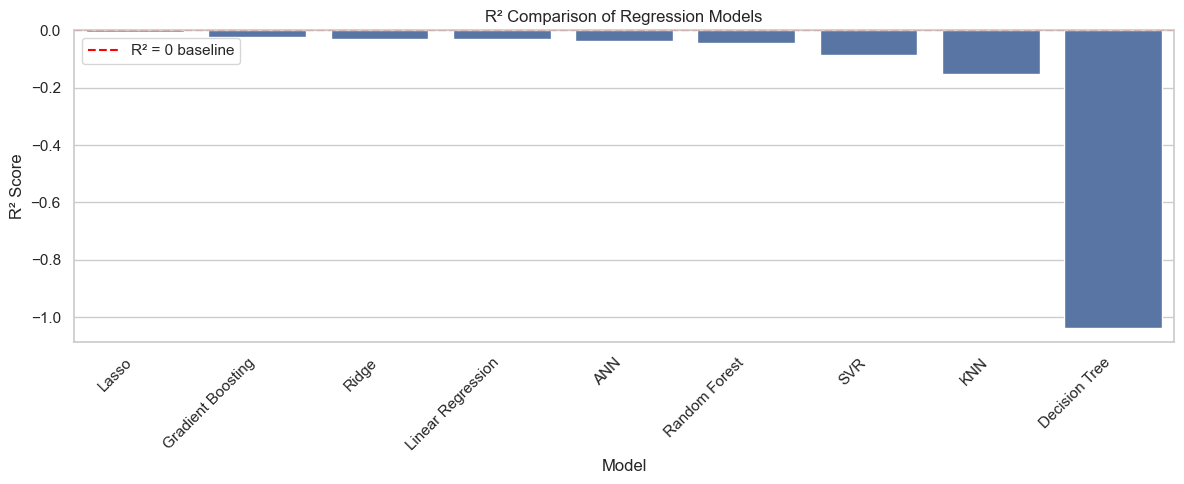

In [13]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="R² = 0 baseline"
)

plt.title("R² Comparison of Regression Models")
plt.xticks(rotation=45, ha="right")
plt.ylabel("R² Score")
plt.legend()
plt.tight_layout()
plt.show()

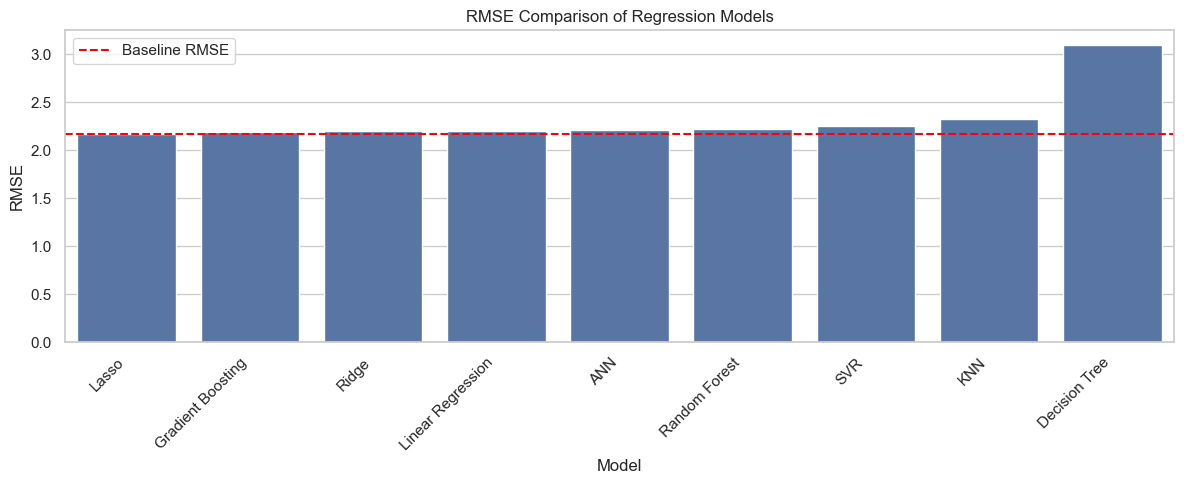

In [14]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.axhline(
    y=baseline_rmse,
    color="red",
    linestyle="--",
    label="Baseline RMSE"
)

plt.title("RMSE Comparison of Regression Models")
plt.xticks(rotation=45, ha="right")
plt.ylabel("RMSE")
plt.legend()
plt.tight_layout()
plt.show()

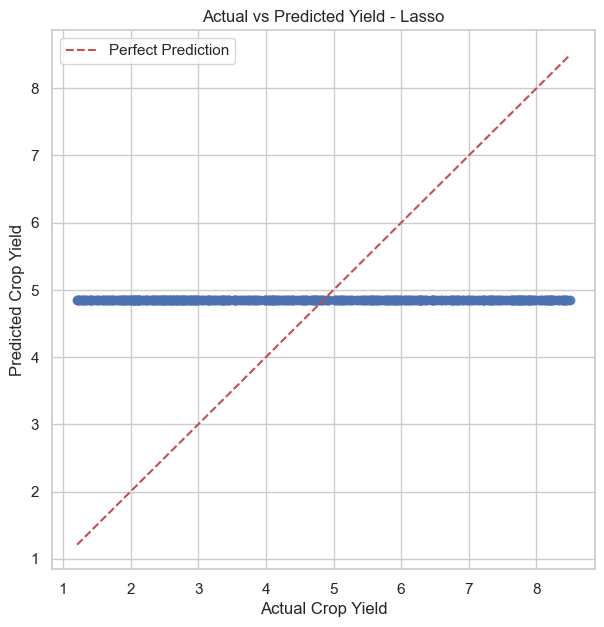

Selected model: Lasso
R²: -0.005359305210754783


In [15]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

best_predictions = best_model.predict(X_test)

plt.figure(figsize=(7, 7))

plt.scatter(
    y_test,
    best_predictions,
    alpha=0.6
)

minimum = min(y_test.min(), best_predictions.min())
maximum = max(y_test.max(), best_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Perfect Prediction"
)

plt.xlabel("Actual Crop Yield")
plt.ylabel("Predicted Crop Yield")
plt.title(f"Actual vs Predicted Yield - {best_model_name}")
plt.legend()
plt.show()

print("Selected model:", best_model_name)
print("R²:", r2_score(y_test, best_predictions))

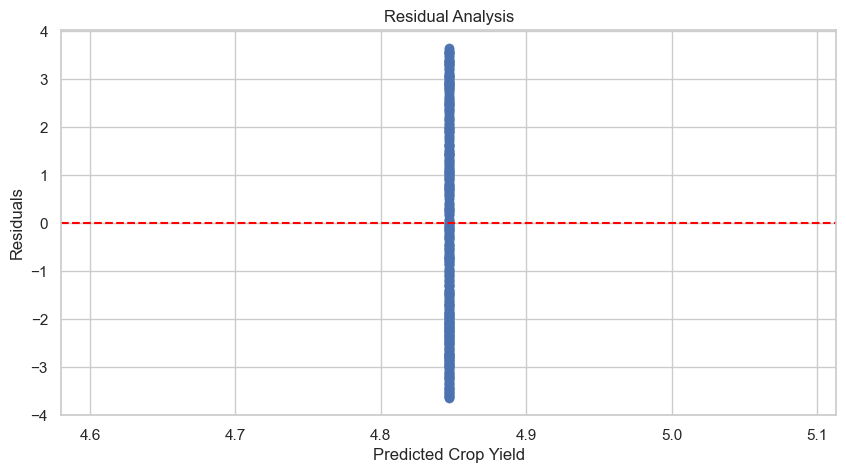

Mean Residual: -0.15861944444444337
Residual Standard Deviation: 2.1682231753979018


In [16]:
residuals = y_test - best_predictions

plt.figure(figsize=(10, 5))

plt.scatter(
    best_predictions,
    residuals,
    alpha=0.6
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted Crop Yield")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()

print("Mean Residual:", residuals.mean())
print("Residual Standard Deviation:", residuals.std())

In [17]:
rf_model = trained_models["Random Forest"]

rf_estimator = rf_model.named_steps["model"]

feature_names = (
    rf_model.named_steps["preprocessing"]
    .get_feature_names_out()
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_estimator.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df.head(15))

,Feature,Importance
34,numerical__Cultivated_Area_hectares,0.128852
33,numerical__Pesticide_Used_kg,0.127564
29,numerical__Rainfall_mm,0.124936
32,numerical__Fertilizer_Used_kg,0.124646
31,numerical__Humidity_percent,0.121476
30,numerical__Avg_Temperature_C,0.112461
8,categorical__Season_Kharif,0.011484
9,categorical__Season_Rabi,0.011445
10,categorical__Season_Zaid,0.011062
24,categorical__Irrigation_Type_Canal,0.010647


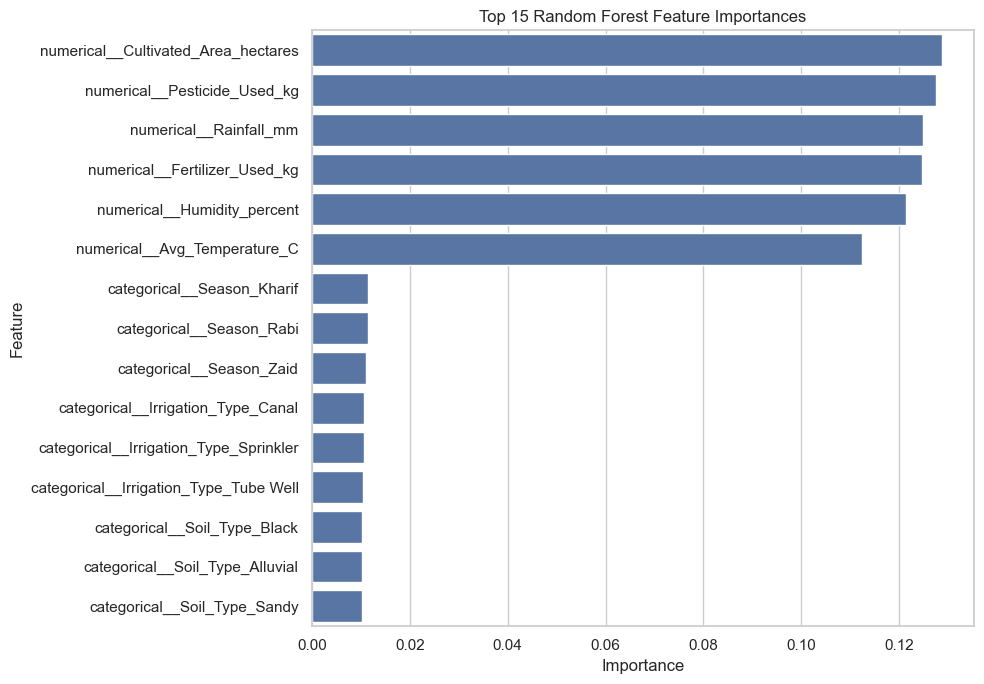

In [18]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Random Forest Feature Importances")
plt.tight_layout()
plt.show()

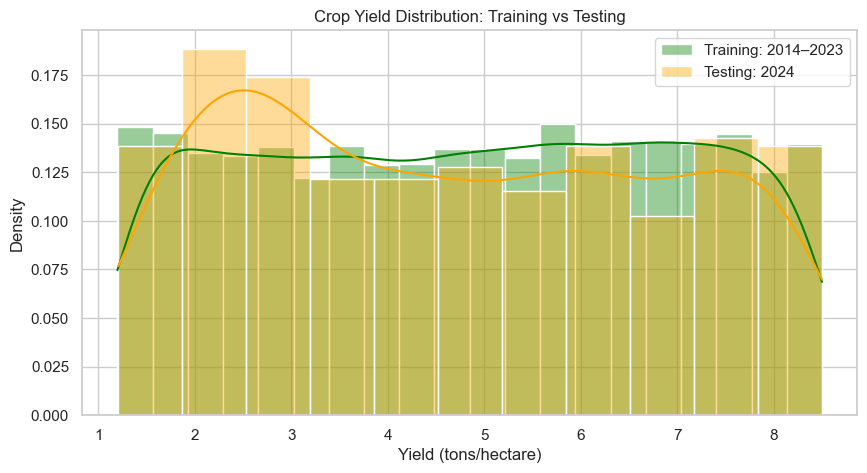

Training mean: 4.846633333333332
Testing mean: 4.6880138888888885
Training standard deviation: 2.1235445157052792
Testing standard deviation: 2.1682231753979018


In [19]:
plt.figure(figsize=(10, 5))

sns.histplot(
    y_train,
    color="green",
    label="Training: 2014–2023",
    kde=True,
    stat="density",
    alpha=0.4
)

sns.histplot(
    y_test,
    color="orange",
    label="Testing: 2024",
    kde=True,
    stat="density",
    alpha=0.4
)

plt.title("Crop Yield Distribution: Training vs Testing")
plt.xlabel("Yield (tons/hectare)")
plt.legend()
plt.show()

print("Training mean:", y_train.mean())
print("Testing mean:", y_test.mean())

print("Training standard deviation:", y_train.std())
print("Testing standard deviation:", y_test.std())

In [20]:
# Sort training records chronologically
train_sorted = train_data.sort_values("Year").copy()

X_cv = train_sorted[features]
y_cv = train_sorted[target]

tscv = TimeSeriesSplit(n_splits=5)

cv_results = []

for name, algorithm in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", algorithm)
    ])

    scores = cross_validate(
        pipeline,
        X_cv,
        y_cv,
        cv=tscv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2"
        },
        error_score="raise"
    )

    cv_results.append({
        "Model": name,
        "Mean MAE": -scores["test_mae"].mean(),
        "Mean RMSE": np.sqrt(-scores["test_mse"].mean()),
        "Mean R2": scores["test_r2"].mean(),
        "R2 Std": scores["test_r2"].std()
    })

cv_results_df = pd.DataFrame(cv_results)

cv_results_df = cv_results_df.sort_values(
    by="Mean RMSE"
)

display(cv_results_df.round(4))

,Model,Mean MAE,Mean RMSE,Mean R2,R2 Std
7,Lasso,1.8359,2.1205,-0.0010,0.0012
6,Gradient Boosting,1.8433,2.1336,-0.0132,0.0193
8,Ridge,1.8457,2.1360,-0.0155,0.0231
0,Linear Regression,1.8458,2.1361,-0.0156,0.0232
5,ANN,1.8516,2.1482,-0.0270,0.0260
2,Random Forest,1.8592,2.1585,-0.0370,0.0165
3,SVR,1.8856,2.1984,-0.0753,0.0261
4,KNN,1.9553,2.3119,-0.1894,0.0175
1,Decision Tree,2.4837,3.0298,-1.0432,0.0540


In [21]:
from sklearn.decomposition import PCA

numeric_preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=0.99))
])

pca_pipeline = Pipeline([
    ("preprocessing", numeric_preprocessor),
    (
        "model",
        RandomForestRegressor(
            n_estimators=150,
            random_state=42,
            min_samples_leaf=2
        )
    )
])

X_train_numeric = X_train[numeric_features]
X_test_numeric = X_test[numeric_features]

pca_pipeline.fit(X_train_numeric, y_train)

pca_predictions = pca_pipeline.predict(X_test_numeric)

print("PCA Random Forest Results")
print("-------------------------")

print(
    "MAE:",
    mean_absolute_error(y_test, pca_predictions)
)

print(
    "RMSE:",
    np.sqrt(mean_squared_error(y_test, pca_predictions))
)

print(
    "R2:",
    r2_score(y_test, pca_predictions)
)

print(
    "Number of principal components:",
    pca_pipeline.named_steps["preprocessing"]
    .named_steps["pca"].n_components_
)

PCA Random Forest Results
-------------------------
MAE: 1.9335763536563744
RMSE: 2.2112780810242083
R2: -0.04155537364904882
Number of principal components: 6


In [22]:
target = "Farmer_Profit_INR"

profit_features = (
    categorical_features
    + numeric_features
    + ["Yield_ton_per_hectare"]
)

profit_data = df.dropna(
    subset=[target, "Year"]
).copy()

X_profit = profit_data[profit_features].copy()
y_profit = pd.to_numeric(
    profit_data[target],
    errors="coerce"
)

for col in numeric_features + ["Yield_ton_per_hectare"]:
    X_profit[col] = pd.to_numeric(
        X_profit[col],
        errors="coerce"
    )

valid = y_profit.notna()

X_profit = X_profit.loc[valid]
y_profit = y_profit.loc[valid]
profit_data = profit_data.loc[valid]

profit_train = profit_data[profit_data["Year"] < 2024]
profit_test = profit_data[profit_data["Year"] == 2024]

X_train_profit = X_profit.loc[profit_train.index]
X_test_profit = X_profit.loc[profit_test.index]

y_train_profit = y_profit.loc[profit_train.index]
y_test_profit = y_profit.loc[profit_test.index]

print("Profitability training records:", len(X_train_profit))
print("Profitability testing records:", len(X_test_profit))

Profitability training records: 7200
Profitability testing records: 720


In [23]:
# Identify feature types

profit_categorical_features = X_train_profit.select_dtypes(
    include=["object", "category"]
).columns.tolist()

profit_numeric_features = X_train_profit.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical Features:")
print(profit_categorical_features)

print("\nNumerical Features:")
print(profit_numeric_features)

Categorical Features:
['State', 'Season', 'Crop_Type', 'Soil_Type', 'Irrigation_Type']

Numerical Features:
['Rainfall_mm', 'Avg_Temperature_C', 'Humidity_percent', 'Fertilizer_Used_kg', 'Pesticide_Used_kg', 'Cultivated_Area_hectares', 'Yield_ton_per_hectare']


In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

# Numerical preprocessing
profit_numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
profit_categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
profit_preprocessor = ColumnTransformer(
    transformers=[
        ("num", profit_numeric_transformer, profit_numeric_features),
        ("cat", profit_categorical_transformer, profit_categorical_features)
    ]
)

print("Profitability preprocessing completed.")

Profitability preprocessing completed.


In [25]:
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

models_profit = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=150,
        random_state=42,
        min_samples_leaf=2
    ),

    "SVR": SVR(),

    "KNN": KNeighborsRegressor(
        n_neighbors=5
    ),

    "ANN": MLPRegressor(
        hidden_layer_sizes=(100, 50),
        max_iter=1000,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

    "Lasso": Lasso(alpha=0.1),

    "Ridge": Ridge(alpha=1.0)
}

print("Total Models:", len(models_profit))

Total Models: 9


In [26]:
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

profit_results = []
profit_trained_models = {}

for name, model in models_profit.items():

    pipeline = Pipeline(steps=[
        ("preprocessor", profit_preprocessor),
        ("model", model)
    ])

    # Train model
    pipeline.fit(X_train_profit, y_train_profit)

    # Predict
    y_pred = pipeline.predict(X_test_profit)

    # Evaluate
    mae = mean_absolute_error(y_test_profit, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_test_profit, y_pred)
    )

    r2 = r2_score(y_test_profit, y_pred)

    profit_results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    })

    profit_trained_models[name] = pipeline

# Create results table
profit_results_df = pd.DataFrame(profit_results)

profit_results_df = profit_results_df.sort_values(
    by="R2 Score",
    ascending=False
).reset_index(drop=True)

display(profit_results_df.round(3))

best_profit_model_name = profit_results_df.loc[0, "Model"]

best_profit_model = profit_trained_models[
    best_profit_model_name
]

print("Best Model:", best_profit_model_name)
print("MAE:", round(profit_results_df.loc[0, "MAE"], 2))
print("RMSE:", round(profit_results_df.loc[0, "RMSE"], 2))
print("R2 Score:", round(profit_results_df.loc[0, "R2 Score"], 4))

,Model,MAE,RMSE,R2 Score
0,Gradient Boosting,32003.795,45076.960,0.862
1,Random Forest,31827.725,45934.293,0.856
2,ANN,35992.871,48844.845,0.838
3,Ridge,47561.821,59004.206,0.763
4,Lasso,47565.178,59006.050,0.763
5,Linear Regression,47565.253,59006.144,0.763
6,Decision Tree,41253.485,62912.450,0.730
7,KNN,46888.337,63139.704,0.728
8,SVR,94472.486,123073.413,-0.032


Best Model: Gradient Boosting
MAE: 32003.8
RMSE: 45076.96
R2 Score: 0.8616


In [27]:
import plotly.express as px

fig = px.bar(
    profit_results_df,
    x="Model",
    y="R2 Score",
    color="Model",
    title="Farmer Profitability - Model Comparison",
    color_discrete_sequence=[
        "#237A45", "#239B9B", "#D9A441",
        "#5276A7", "#8E6BBF", "#C76D4D",
        "#4C9A76", "#7B8794", "#B05A8F"
    ]
)

fig.update_layout(
    xaxis_title="Machine Learning Models",
    yaxis_title="R² Score",
    font=dict(color="black"),
    title_font_color="black",
    showlegend=False
)

fig.show()

In [28]:
profit_predictions = best_profit_model.predict(
    X_test_profit
)

profit_comparison = pd.DataFrame({
    "Actual Profit": y_test_profit.values,
    "Predicted Profit": profit_predictions
})

fig = px.scatter(
    profit_comparison,
    x="Actual Profit",
    y="Predicted Profit",
    title="Actual vs Predicted Farmer Profitability",
    color_discrete_sequence=["#239B9B"]
)

min_val = min(
    profit_comparison["Actual Profit"].min(),
    profit_comparison["Predicted Profit"].min()
)

max_val = max(
    profit_comparison["Actual Profit"].max(),
    profit_comparison["Predicted Profit"].max()
)

fig.add_shape(
    type="line",
    x0=min_val,
    y0=min_val,
    x1=max_val,
    y1=max_val,
    line=dict(color="red", dash="dash")
)

fig.update_layout(
    xaxis_title="Actual Profit (INR)",
    yaxis_title="Predicted Profit (INR)",
    font=dict(color="black"),
    title_font_color="black"
)

fig.show()

In [29]:
profit_error = y_test_profit.values - profit_predictions

profit_error_df = pd.DataFrame({
    "Actual Profit": y_test_profit.values,
    "Predicted Profit": profit_predictions,
    "Error": profit_error
})

display(profit_error_df.head(10))

print("Mean Absolute Error:",
      round(mean_absolute_error(y_test_profit, profit_predictions), 2))

print("Mean Prediction Error:",
      round(np.mean(profit_error), 2))

,Actual Profit,Predicted Profit,Error
0,60030.0,73606.629188,-13576.629188
1,46477.0,53706.194533,-7229.194533
2,333285.0,323007.774994,10277.225006
3,27474.0,43006.443434,-15532.443434
4,169465.0,211773.918929,-42308.918929
5,11125.0,21399.178486,-10274.178486
6,133055.0,121595.355847,11459.644153
7,30162.0,24466.812781,5695.187219
8,398364.0,343450.147515,54913.852485
9,57068.0,70122.849616,-13054.849616


Mean Absolute Error: 32003.8
Mean Prediction Error: -1690.17


In [30]:
fig = px.scatter(
    x=profit_predictions,
    y=profit_error,
    title="Residual Analysis - Farmer Profitability",
    labels={
        "x": "Predicted Profit (INR)",
        "y": "Residual Error (INR)"
    },
    color_discrete_sequence=["#D9A441"]
)

fig.add_hline(
    y=0,
    line_dash="dash",
    line_color="red"
)

fig.update_layout(
    font=dict(color="black"),
    title_font_color="black"
)

fig.show()

In [31]:
rf_profit = profit_trained_models["Random Forest"]

feature_names = rf_profit.named_steps[
    "preprocessor"
].get_feature_names_out()

feature_importance = rf_profit.named_steps[
    "model"
].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).head(15)

fig = px.bar(
    importance_df.sort_values("Importance"),
    x="Importance",
    y="Feature",
    orientation="h",
    title="Top 15 Features Influencing Farmer Profitability",
    color_discrete_sequence=["#237A45"]
)

fig.update_layout(
    xaxis_title="Feature Importance",
    yaxis_title="Features",
    font=dict(color="black"),
    title_font_color="black"
)

fig.show()

In [32]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score

# Sort training records chronologically
train_order = profit_train.loc[
    X_train_profit.index, "Year"
].sort_values().index

X_train_profit_sorted = X_train_profit.loc[train_order]
y_train_profit_sorted = y_train_profit.loc[train_order]

tscv_profit = TimeSeriesSplit(n_splits=5)

cv_scores_profit = cross_val_score(
    best_profit_model,
    X_train_profit_sorted,
    y_train_profit_sorted,
    cv=tscv_profit,
    scoring="r2"
)

print("Cross-validation R² Scores:")
print(cv_scores_profit)

print("Average CV R²:", round(cv_scores_profit.mean(), 4))
print("Standard Deviation:", round(cv_scores_profit.std(), 4))

Cross-validation R² Scores:
[0.86815356 0.8749497  0.86674237 0.87148239 0.87564469]
Average CV R²: 0.8714
Standard Deviation: 0.0035


In [33]:
import joblib

joblib.dump(
    best_profit_model,
    "farmer_profitability_model.pkl"
)

print("Farmer Profitability Model Saved Successfully!")

Farmer Profitability Model Saved Successfully!


In [34]:
# =====================================================
# CROP YIELD FORECASTING & MODEL EXPORT
# =====================================================
# Fits the best model on all available records, saves crop_yield_model.pkl
# for the Streamlit dashboard, and executes an end-to-end forecasting scenario.

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import plotly.express as px
import pandas as pd
from IPython.display import display
import joblib

yield_target = "Yield_ton_per_hectare"
forecast_categorical_features = [
    "State", "Season", "Crop_Type", "Soil_Type", "Irrigation_Type"
]
forecast_numeric_features = [
    "Rainfall_mm", "Avg_Temperature_C", "Humidity_percent",
    "Fertilizer_Used_kg", "Pesticide_Used_kg", "Cultivated_Area_hectares"
]
forecast_features = forecast_categorical_features + forecast_numeric_features

forecast_df = df.copy()
for column in forecast_numeric_features + [yield_target]:
    forecast_df[column] = pd.to_numeric(forecast_df[column], errors="coerce")
forecast_df = forecast_df.dropna(subset=[yield_target]).copy()

forecast_preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), forecast_categorical_features),
        ("numerical", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), forecast_numeric_features)
    ]
)

yield_forecast_model = Pipeline([
    ("preprocessing", forecast_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=150, random_state=42, min_samples_leaf=2
    ))
])
yield_forecast_model.fit(
    forecast_df[forecast_features], forecast_df[yield_target]
)
print("Crop-yield forecasting model successfully trained on", len(forecast_df), "records.")

# Save the trained model for the Streamlit application
joblib.dump(yield_forecast_model, "crop_yield_model.pkl")
print("Crop Yield Forecasting Model Saved Successfully as 'crop_yield_model.pkl'!")

# Execute a Crop Yield Forecasting Scenario
forecast_input = {
    "State": "Punjab",
    "Season": "Rabi",
    "Crop_Type": "Wheat",
    "Soil_Type": "Alluvial",
    "Irrigation_Type": "Canal",
    "Rainfall_mm": 650.0,
    "Avg_Temperature_C": 22.0,
    "Humidity_percent": 55.0,
    "Fertilizer_Used_kg": 180.0,
    "Pesticide_Used_kg": 8.0,
    "Cultivated_Area_hectares": 5.0
}

forecast_row = pd.DataFrame([forecast_input], columns=forecast_features)
predicted_yield = float(yield_forecast_model.predict(forecast_row)[0])
crop_name = forecast_input["Crop_Type"]
state_name = forecast_input["State"]
overall_average = float(forecast_df[yield_target].mean())

def historical_average(mask):
    values = forecast_df.loc[mask, yield_target]
    return float(values.mean()) if not values.empty else overall_average

crop_average = historical_average(forecast_df["Crop_Type"] == crop_name)
state_average = historical_average(forecast_df["State"] == state_name)
state_crop_average = historical_average(
    (forecast_df["State"] == state_name)
    & (forecast_df["Crop_Type"] == crop_name)
)
percentile = float(
    (forecast_df[yield_target] < predicted_yield).mean() * 100
)
total_output = predicted_yield * float(
    forecast_input["Cultivated_Area_hectares"]
)

if predicted_yield >= 5.5:
    yield_category = "Superior / High Yield Potential"
elif predicted_yield >= 4.5:
    yield_category = "Optimal / Healthy Yield"
elif predicted_yield >= 3.5:
    yield_category = "Moderate Production Potential"
else:
    yield_category = "Below Average / Low Yield"

print(f"\n=======================================================")
print(f"       CROP YIELD FORECASTING SCENARIO RESULT          ")
print(f"=======================================================")
print(f"Crop: {crop_name} | State: {state_name} | Season: {forecast_input['Season']}")
print(f"Soil Type: {forecast_input['Soil_Type']} | Irrigation: {forecast_input['Irrigation_Type']}")
print(f"Cultivated Area: {forecast_input['Cultivated_Area_hectares']:.1f} hectares")
print(f"Predicted Crop Yield: {predicted_yield:.2f} tons/hectare")
print(f"Estimated Total Output: {total_output:.2f} metric tons")
print(f"Yield Classification: {yield_category}")
print(f"Historical Percentile: {percentile:.1f}th percentile")
print(f"=======================================================\n")

yield_benchmarks = pd.DataFrame({
    "Benchmark": [
        "Forecast", f"{crop_name} in {state_name}",
        f"{crop_name} (National)", f"{state_name} (All Crops)",
        "National (All Crops)"
    ],
    "Yield (tons/hectare)": [
        predicted_yield, state_crop_average, crop_average,
        state_average, overall_average
    ]
})
print("Yield Benchmark Comparisons:")
display(yield_benchmarks.round(2))

benchmark_fig = px.bar(
    yield_benchmarks, x="Benchmark", y="Yield (tons/hectare)",
    color="Benchmark", text_auto=".2f",
    title=f"Crop Yield Forecast vs Historical Benchmarks: {crop_name} ({state_name})",
    color_discrete_sequence=["#1B5E20", "#2E7D32", "#43A047", "#81C784", "#B0BEC5"]
)
benchmark_fig.update_layout(showlegend=False, xaxis_tickangle=-25)
benchmark_fig.show()

crop_history = forecast_df.loc[
    forecast_df["Crop_Type"] == crop_name, yield_target
]
history_fig = px.histogram(
    crop_history, x=yield_target, nbins=25,
    title=f"Historical Yield Distribution for {crop_name} (Forecast: {predicted_yield:.2f} t/ha)",
    color_discrete_sequence=["#2E7D32"]
)
history_fig.add_vline(
    x=predicted_yield, line_dash="dash", line_color="red", line_width=3,
    annotation_text=f"Forecast: {predicted_yield:.2f} tons/ha"
)
history_fig.show()


Crop-yield forecasting model successfully trained on 7920 records.
Crop Yield Forecasting Model Saved Successfully as 'crop_yield_model.pkl'!

       CROP YIELD FORECASTING SCENARIO RESULT          
Crop: Wheat | State: Punjab | Season: Rabi
Soil Type: Alluvial | Irrigation: Canal
Cultivated Area: 5.0 hectares
Predicted Crop Yield: 4.31 tons/hectare
Estimated Total Output: 21.57 metric tons
Yield Classification: Moderate Production Potential
Historical Percentile: 42.7th percentile

Yield Benchmark Comparisons:


,Benchmark,Yield (tons/hectare)
0,Forecast,4.31
1,Wheat in Punjab,4.85
2,Wheat (National),4.83
3,Punjab (All Crops),4.88
4,National (All Crops),4.83


In [35]:
# =====================================================
# STREAMLIT WEB APPLICATION
# =====================================================
# To launch the interactive AgriSmart Streamlit app, run:
#   python -m streamlit run app.py
# The Streamlit app loads and uses the best models saved from this notebook:
#   - crop_yield_model.pkl (Best Crop Yield Model)
#   - farmer_profitability_model.pkl (Best Farmer Profitability Model)
print("To launch the AgriSmart Dashboard, run: python -m streamlit run app.py in your terminal.")


To launch the AgriSmart Dashboard, run: python -m streamlit run app.py in your terminal.
